In [3]:

from pathlib import Path
import json
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    precision_recall_curve,
)

warnings.filterwarnings("ignore", category=FutureWarning)

# Project paths
PROJECT_ROOT = Path.cwd()

# Handle running from either the project root or notebooks folder
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_DIR = PROJECT_ROOT / "artifacts" / "models"
METRICS_DIR = PROJECT_ROOT / "artifacts" / "metrics"
ENSEMBLE_DIR = PROJECT_ROOT / "artifacts" / "ensemble"

# Create only the new ensemble output directory
ENSEMBLE_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
N_SPLITS = 5

print("Project root:", PROJECT_ROOT)
print("Model directory exists:", MODEL_DIR.exists())
print("Metrics directory exists:", METRICS_DIR.exists())
print("Ensemble output directory:", ENSEMBLE_DIR)


Project root: e:\hr-job-change-ml
Model directory exists: True
Metrics directory exists: True
Ensemble output directory: e:\hr-job-change-ml\artifacts\ensemble


In [4]:

print("Existing model files:")
for path in sorted(MODEL_DIR.glob("*")):
    print(" -", path.name)

print("\nExisting metric files:")
for path in sorted(METRICS_DIR.glob("*")):
    print(" -", path.name)

metrics_path = METRICS_DIR / "final_test_metrics.csv"

if metrics_path.exists():
    existing_metrics = pd.read_csv(metrics_path)
    print("\nFinal test metrics columns:")
    print(existing_metrics.columns.tolist())
    display(existing_metrics.head())
else:
    print("\nWARNING: final_test_metrics.csv was not found.")


Existing model files:
 - decision_tree.pkl
 - knn.pkl
 - logistic_regression.pkl
 - random_forest.pkl

Existing metric files:
 - baseline_cv_metrics.csv
 - best_thresholds.csv
 - cv_vs_test.csv
 - final_test_metrics.csv
 - random_forest_permutation_importance.csv
 - threshold_comparison.csv
 - tuning_summary.csv

Final test metrics columns:
['Model', 'Threshold', 'Accuracy', 'Precision', 'Recall', 'F1', 'Balanced Accuracy', 'ROC-AUC', 'PR-AUC', 'Log Loss', 'Brier Score']


,Model,Threshold,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC,PR-AUC,Log Loss,Brier Score
0,Logistic Regression,0.30,0.788796,0.557895,0.739191,0.635873,0.772238,0.806008,0.545018,0.448365,0.143417
1,Random Forest,0.56,0.795407,0.568690,0.744770,0.644928,0.778505,0.809383,0.544331,0.519626,0.168815
2,Decision Tree,0.31,0.786708,0.554507,0.737796,0.633154,0.770382,0.803015,0.534296,0.506655,0.139861
3,KNN,0.34,0.777314,0.539007,0.741980,0.624413,0.765520,0.798552,0.511702,0.570866,0.145035


In [5]:

# Load the cleaned dataset used by the official modeling notebook
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "clean_hr_job_change.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Columns:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["target"].value_counts().sort_index())

print("\nTarget proportions:")
print(df["target"].value_counts(normalize=True).sort_index().round(4))

# Confirm that the target and identifier exist
assert "target" in df.columns, "Target column is missing."
assert "enrollee_id" in df.columns, "Expected enrollee_id column is missing."

print("\nDataset loaded successfully.")


Dataset shape: (19158, 16)
Columns:
['enrollee_id', 'city', 'city_development_index', 'gender', 'relevent_experience', 'enrolled_university', 'education_level', 'major_discipline', 'company_size', 'company_type', 'training_hours', 'target', 'experience_missing', 'experience_numeric', 'last_new_job_missing', 'last_new_job_numeric']

Target distribution:
target
0.0    14381
1.0     4777
Name: count, dtype: int64

Target proportions:
target
0.0    0.7507
1.0    0.2493
Name: proportion, dtype: float64

Dataset loaded successfully.


## Recreating original train-test split

In [6]:
from sklearn.model_selection import train_test_split

# Exclude the identifier from model features
X = df.drop(columns=["enrollee_id", "target"])
y = df["target"].astype(int)

# Recreate the official split
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y,
)

print("Development features:", X_dev.shape)
print("Final test features:", X_test.shape)

print("\nDevelopment target proportions:")
print(y_dev.value_counts(normalize=True).sort_index().round(4))

print("\nFinal test target proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(4))

assert len(X_test) == 2874, "Test split size differs from the expected official split."

print("\nSplit recreated successfully.")


Development features: (16284, 14)
Final test features: (2874, 14)

Development target proportions:
target
0    0.7507
1    0.2493
Name: proportion, dtype: float64

Final test target proportions:
target
0    0.7505
1    0.2495
Name: proportion, dtype: float64

Split recreated successfully.


In [7]:
model_files = {
    "Logistic Regression": MODEL_DIR / "logistic_regression.pkl",
    "KNN": MODEL_DIR / "knn.pkl",
    "Decision Tree": MODEL_DIR / "decision_tree.pkl",
    "Random Forest": MODEL_DIR / "random_forest.pkl",
}

models = {}

for name, path in model_files.items():
    with open(path, "rb") as file:
        model = pickle.load(file)

    models[name] = model

    print(f"\n{name}")
    print("  Object type:", type(model).__name__)
    print("  Has predict_proba:", hasattr(model, "predict_proba"))
    print("  Has named steps:", hasattr(model, "named_steps"))

    if hasattr(model, "named_steps"):
        print("  Pipeline steps:", list(model.named_steps.keys()))
    elif hasattr(model, "get_params"):
        print("  Estimator parameters:")
        print(model.get_params())



Logistic Regression
  Object type: Pipeline
  Has predict_proba: True
  Has named steps: True
  Pipeline steps: ['preprocessor', 'model']

KNN
  Object type: Pipeline
  Has predict_proba: True
  Has named steps: True
  Pipeline steps: ['preprocessor', 'model']

Decision Tree
  Object type: Pipeline
  Has predict_proba: True
  Has named steps: True
  Pipeline steps: ['preprocessor', 'model']

Random Forest
  Object type: Pipeline
  Has predict_proba: True
  Has named steps: True
  Pipeline steps: ['preprocessor', 'model']


In [8]:

expected_parameters = {
    "Logistic Regression": {
        "C": 0.1,
        "class_weight": None,
    },
    "KNN": {
        "n_neighbors": 21,
        "weights": "uniform",
        "p": 1,
    },
    "Decision Tree": {
        "max_depth": 7,
        "min_samples_leaf": 5,
        "min_samples_split": 20,
        "class_weight": None,
    },
    "Random Forest": {
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 5,
        "min_samples_split": 2,
        "class_weight": "balanced",
    },
}

for name, pipeline in models.items():
    estimator = pipeline.named_steps["model"]
    actual = estimator.get_params()

    print(f"\n{name}")
    for parameter, expected in expected_parameters[name].items():
        value = actual.get(parameter)
        status = "OK" if value == expected else "CHECK"
        print(
            f"  {parameter}: {value!r} "
            f"(expected {expected!r}) [{status}]"
        )



Logistic Regression
  C: 0.1 (expected 0.1) [OK]
  class_weight: None (expected None) [OK]

KNN
  n_neighbors: 21 (expected 21) [OK]
  weights: 'uniform' (expected 'uniform') [OK]
  p: 1 (expected 1) [OK]

Decision Tree
  max_depth: 7 (expected 7) [OK]
  min_samples_leaf: 5 (expected 5) [OK]
  min_samples_split: 20 (expected 20) [OK]
  class_weight: None (expected None) [OK]

Random Forest
  n_estimators: 200 (expected 200) [OK]
  max_depth: None (expected None) [OK]
  min_samples_leaf: 5 (expected 5) [OK]
  min_samples_split: 2 (expected 2) [OK]
  class_weight: 'balanced' (expected 'balanced') [OK]


In [9]:
from IPython.display import display as show_table
from sklearn.model_selection import StratifiedKFold, cross_val_predict

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

oof_probabilities = pd.DataFrame(index=X_dev.index)

for name, pipeline in models.items():
    print(f"Generating OOF probabilities: {name}")

    probabilities = cross_val_predict(
        clone(pipeline),
        X_dev,
        y_dev,
        cv=cv,
        method="predict_proba",
        n_jobs=-1,
    )[:, 1]

    column_name = {
        "Logistic Regression": "lr_probability",
        "KNN": "knn_probability",
        "Decision Tree": "dt_probability",
        "Random Forest": "rf_probability",
    }[name]

    oof_probabilities[column_name] = probabilities

oof_probabilities["target"] = y_dev

print("\nOOF dataset shape:", oof_probabilities.shape)
show_table(oof_probabilities.head())

assert oof_probabilities.isna().sum().sum() == 0
assert oof_probabilities.shape[0] == len(X_dev)

print("OOF probabilities generated successfully.")


Generating OOF probabilities: Logistic Regression


Generating OOF probabilities: KNN
Generating OOF probabilities: Decision Tree
Generating OOF probabilities: Random Forest

OOF dataset shape: (16284, 5)


,lr_probability,knn_probability,dt_probability,rf_probability,target
9208,0.062140,0.142857,0.066639,0.197866,0
18774,0.392648,0.476190,0.465812,0.742940,0
17725,0.496809,0.571429,0.532095,0.736519,0
8652,0.036405,0.095238,0.091333,0.198028,0
17892,0.128158,0.047619,0.056738,0.148504,0


OOF probabilities generated successfully.


In [10]:

# Names of the four OOF probability columns
probability_columns = [
    "lr_probability",
    "knn_probability",
    "dt_probability",
    "rf_probability",
]

# Average the four probabilities for Soft Voting
soft_voting_oof = oof_probabilities[probability_columns].mean(axis=1)

print("Soft Voting OOF probability summary:")
print(soft_voting_oof.describe().round(4))

assert soft_voting_oof.between(0, 1).all()

print("\nSoft Voting probabilities created successfully.")


Soft Voting OOF probability summary:
count    16284.0000
mean         0.2960
std          0.2161
min          0.0473
25%          0.1207
50%          0.1864
75%          0.5287
max          0.8820
dtype: float64

Soft Voting probabilities created successfully.


In [11]:
# The meta-model learns from OOF probabilities, not in-sample predictions
X_meta = oof_probabilities[probability_columns].copy()
y_meta = oof_probabilities["target"].astype(int)

stacking_meta_model = LogisticRegression(
    max_iter=2000,
    random_state=RANDOM_STATE,
)

stacking_meta_model.fit(X_meta, y_meta)

# Stacking probabilities on the same OOF meta-features are useful
# for initial threshold selection, but are in-sample for the meta-model.
stacking_oof_probabilities = stacking_meta_model.predict_proba(X_meta)[:, 1]

print("Stacking meta-model trained.")
print("Meta-model coefficients:")
print(pd.Series(
    stacking_meta_model.coef_[0],
    index=probability_columns
).round(4))

print("\nIntercept:", round(stacking_meta_model.intercept_[0], 4))

Stacking meta-model trained.
Meta-model coefficients:
lr_probability     0.3236
knn_probability    0.4106
dt_probability     1.0551
rf_probability     3.5389
dtype: float64

Intercept: -3.3684


In [12]:
from sklearn.model_selection import cross_val_predict

def find_best_f1_threshold(y_true, probabilities):
    """Return the threshold that maximizes F1."""
    precision, recall, thresholds = precision_recall_curve(
        y_true, probabilities
    )

    # The final precision/recall point has no corresponding threshold
    precision = precision[:-1]
    recall = recall[:-1]

    f1_scores = (
        2 * precision * recall
        / (precision + recall + 1e-12)
    )

    best_index = int(np.argmax(f1_scores))

    return float(thresholds[best_index]), float(f1_scores[best_index])


# Soft Voting threshold from OOF probabilities
soft_threshold, soft_oof_f1 = find_best_f1_threshold(
    y_dev,
    soft_voting_oof,
)

# Cross-validated predictions for the stacking meta-model
meta_cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE + 1,
)

stacking_cv_probabilities = cross_val_predict(
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    X_meta,
    y_meta,
    cv=meta_cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

stacking_threshold, stacking_oof_f1 = find_best_f1_threshold(
    y_meta,
    stacking_cv_probabilities,
)

ensemble_thresholds = {
    "Soft Voting": soft_threshold,
    "Stacking": stacking_threshold,
}

print("Selected ensemble thresholds:")
for name, threshold in ensemble_thresholds.items():
    print(f"{name}: {threshold:.4f}")

print("\nOOF F1 at selected thresholds:")
print(f"Soft Voting: {soft_oof_f1:.4f}")
print(f"Stacking:    {stacking_oof_f1:.4f}")

Selected ensemble thresholds:
Soft Voting: 0.3886
Stacking: 0.3017

OOF F1 at selected thresholds:
Soft Voting: 0.6344
Stacking:    0.6378


In [13]:
fitted_base_models = {}

for name, pipeline in models.items():
    fitted_model = clone(pipeline)
    fitted_model.fit(X_dev, y_dev)

    fitted_base_models[name] = fitted_model
    print(f"{name}: refitted on development data")

print("\nAll four base models are ready for final-test prediction.")

Logistic Regression: refitted on development data
KNN: refitted on development data
Decision Tree: refitted on development data
Random Forest: refitted on development data

All four base models are ready for final-test prediction.


In [14]:
test_probabilities = pd.DataFrame(index=X_test.index)

test_column_names = {
    "Logistic Regression": "lr_probability",
    "KNN": "knn_probability",
    "Decision Tree": "dt_probability",
    "Random Forest": "rf_probability",
}

for name, fitted_model in fitted_base_models.items():
    column = test_column_names[name]

    test_probabilities[column] = fitted_model.predict_proba(X_test)[:, 1]

# Soft Voting: average the four base-model probabilities
test_probabilities["Soft Voting"] = (
    test_probabilities[probability_columns].mean(axis=1)
)

# Stacking: apply the fitted meta-model to the four test probabilities
stacking_meta_model.fit(X_meta, y_meta)

test_probabilities["Stacking"] = stacking_meta_model.predict_proba(
    test_probabilities[probability_columns]
)[:, 1]

print("Test probability matrix:", test_probabilities.shape)
print(test_probabilities[["Soft Voting", "Stacking"]].describe().round(4).to_string())

assert test_probabilities.notna().all().all()
assert test_probabilities[["Soft Voting", "Stacking"]].ge(0).all().all()
assert test_probabilities[["Soft Voting", "Stacking"]].le(1).all().all()

print("\nFinal-test probabilities generated.")

Test probability matrix: (2874, 6)
       Soft Voting   Stacking
count    2874.0000  2874.0000
mean        0.3016     0.2567
std         0.2202     0.2269
min         0.0533     0.0497
25%         0.1195     0.0790
50%         0.1881     0.1189
75%         0.5500     0.5245
max         0.8131     0.7479

Final-test probabilities generated.


In [15]:

def calculate_metrics(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)

    return {
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_true, predictions),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities),
        "Log Loss": log_loss(y_true, probabilities, labels=[0, 1]),
        "Brier Score": brier_score_loss(y_true, probabilities),
    }


ensemble_results = []

for name in ["Soft Voting", "Stacking"]:
    scores = calculate_metrics(
        y_test,
        test_probabilities[name],
        ensemble_thresholds[name],
    )

    scores["Model"] = name
    ensemble_results.append(scores)

ensemble_metrics = pd.DataFrame(ensemble_results)

column_order = [
    "Model", "Threshold", "Accuracy", "Precision", "Recall", "F1",
    "Balanced Accuracy", "ROC-AUC", "PR-AUC", "Log Loss", "Brier Score",
]

ensemble_metrics = ensemble_metrics[column_order]

print(ensemble_metrics.round(4).to_string(index=False))


      Model  Threshold  Accuracy  Precision  Recall     F1  Balanced Accuracy  ROC-AUC  PR-AUC  Log Loss  Brier Score
Soft Voting     0.3886    0.7947     0.5678  0.7420 0.6433             0.7771   0.8120  0.5435    0.4397       0.1398
   Stacking     0.3017    0.7971     0.5714  0.7476 0.6477             0.7806   0.8109  0.5464    0.4275       0.1366


## Building a Complete Comparision table

In [16]:
# Load the existing final-test results for the four original models.
baseline_path = METRICS_DIR / "final_test_metrics.csv"
baseline_metrics = pd.read_csv(baseline_path)

# Keep the original results unchanged and add the ensemble results.
comparison_metrics = pd.concat([baseline_metrics, ensemble_metrics], ignore_index=True)

comparison_metrics = comparison_metrics.sort_values(by="F1", ascending=False).reset_index(drop=True)

print("Final-test comparison of all six models:")
print(comparison_metrics.round(4).to_string(index=False))

Final-test comparison of all six models:
              Model  Threshold  Accuracy  Precision  Recall     F1  Balanced Accuracy  ROC-AUC  PR-AUC  Log Loss  Brier Score
           Stacking     0.3017    0.7971     0.5714  0.7476 0.6477             0.7806   0.8109  0.5464    0.4275       0.1366
      Random Forest     0.5600    0.7954     0.5687  0.7448 0.6449             0.7785   0.8094  0.5443    0.5196       0.1688
        Soft Voting     0.3886    0.7947     0.5678  0.7420 0.6433             0.7771   0.8120  0.5435    0.4397       0.1398
Logistic Regression     0.3000    0.7888     0.5579  0.7392 0.6359             0.7722   0.8060  0.5450    0.4484       0.1434
      Decision Tree     0.3100    0.7867     0.5545  0.7378 0.6332             0.7704   0.8030  0.5343    0.5067       0.1399
                KNN     0.3400    0.7773     0.5390  0.7420 0.6244             0.7655   0.7986  0.5117    0.5709       0.1450


In [17]:

# Save ensemble evaluation results and inference artifacts.
import json
import pickle

# 1. Save ensemble metrics and the full six-model comparison.
ensemble_metrics.to_csv(ENSEMBLE_DIR / "ensemble_metrics.csv", index=False)

comparison_metrics.to_csv(ENSEMBLE_DIR / "all_models_comparison.csv",index=False)

# 2. Save the selected classification thresholds.
with open(ENSEMBLE_DIR / "ensemble_thresholds.json", "w") as file:
    json.dump(ensemble_thresholds, file, indent=4)

# 3. Save model configuration and probability-column order.
ensemble_parameters = {
    "ensemble_models": ["Soft Voting", "Stacking"],
    "base_models": list(models.keys()),
    "probability_columns": probability_columns,
    "stacking_meta_model": "LogisticRegression",
    "stacking_meta_parameters": {
        "max_iter": 2000,
        "random_state": 42
    },
    "cross_validation": {
        "method": "StratifiedKFold",
        "n_splits": N_SPLITS,
        "shuffle": True,
        "random_state": RANDOM_STATE
    },
    "threshold_selection_metric": "F1",
    "thresholds": ensemble_thresholds
}

with open(ENSEMBLE_DIR / "ensemble_parameters.json", "w") as file:
    json.dump(ensemble_parameters, file, indent=4)

# 4. Save final-test probabilities and threshold-based predictions.
saved_predictions = pd.DataFrame(index=X_test.index)
saved_predictions["actual_target"] = y_test

for column in probability_columns:
    saved_predictions[column] = test_probabilities[column]

for name in ["Soft Voting", "Stacking"]:
    saved_predictions[f"{name}_probability"] = test_probabilities[name]
    saved_predictions[f"{name}_prediction"] = (
        test_probabilities[name] >= ensemble_thresholds[name]
    ).astype(int)

saved_predictions.to_csv(
    ENSEMBLE_DIR / "ensemble_test_predictions.csv",
    index_label="original_row_index"
)

# 5. Save the fitted components needed for future inference.
ensemble_bundle = {
    "base_models": fitted_base_models,
    "stacking_meta_model": stacking_meta_model,
    "probability_columns": probability_columns,
    "thresholds": ensemble_thresholds,
    "base_model_column_names": test_column_names,
    "model_names": list(models.keys())
}

with open(ENSEMBLE_DIR / "ensemble_bundle.pkl", "wb") as file:
    pickle.dump(ensemble_bundle, file)

# 6. Confirm the saved files.
print("Saved ensemble artifacts:")
for path in sorted(ENSEMBLE_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name} — {path.stat().st_size / 1024:.1f} KB")


Saved ensemble artifacts:
all_models_comparison.csv — 1.3 KB
ensemble_bundle.pkl — 18125.3 KB
ensemble_metrics.csv — 0.5 KB
ensemble_parameters.json — 0.8 KB
ensemble_test_predictions.csv — 359.1 KB
ensemble_thresholds.json — 0.1 KB


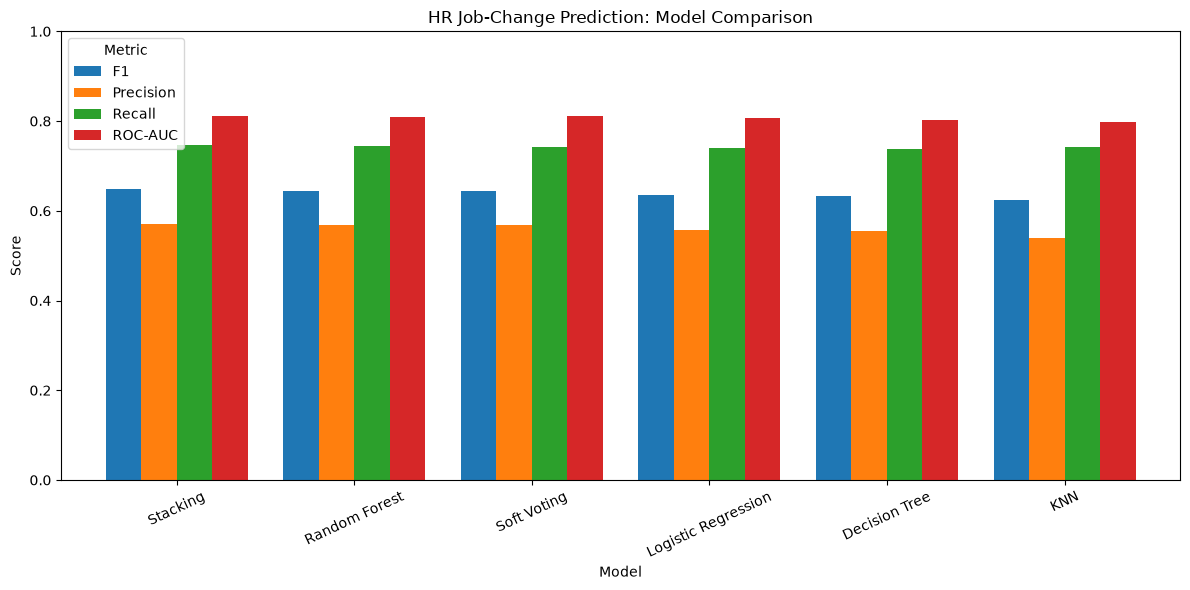

Plot saved to: e:\hr-job-change-ml\artifacts\ensemble\model_comparison.png


In [18]:

# Compare the six models using the main classification metrics.
plot_metrics = [
    "F1",
    "Precision",
    "Recall",
    "ROC-AUC"
]

plot_data = comparison_metrics.set_index("Model")[plot_metrics]

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("HR Job-Change Prediction: Model Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
ax.legend(title="Metric")
ax.tick_params(axis="x", rotation=25)

plt.tight_layout()

plot_path = ENSEMBLE_DIR / "model_comparison.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Plot saved to: {plot_path}")


In [19]:

# Reload the saved bundle and verify its predictions.
bundle_path = ENSEMBLE_DIR / "ensemble_bundle.pkl"

with open(bundle_path, "rb") as file:
    loaded_bundle = pickle.load(file)

loaded_base_models = loaded_bundle["base_models"]
loaded_meta_model = loaded_bundle["stacking_meta_model"]
loaded_columns = loaded_bundle["probability_columns"]

# Recalculate probabilities using the saved base models.
reloaded_probabilities = pd.DataFrame(index=X_test.index)

for name, model in loaded_base_models.items():
    column = loaded_bundle["base_model_column_names"][name]
    reloaded_probabilities[column] = model.predict_proba(X_test)[:, 1]

# Recreate both ensemble predictions.
reloaded_probabilities["Soft Voting"] = (
    reloaded_probabilities[loaded_columns].mean(axis=1)
)

reloaded_probabilities["Stacking"] = loaded_meta_model.predict_proba(
    reloaded_probabilities[loaded_columns]
)[:, 1]

# Compare with the probabilities produced before saving.
for name in ["Soft Voting", "Stacking"]:
    matches = np.allclose(
        reloaded_probabilities[name].to_numpy(),
        test_probabilities[name].to_numpy(),
        rtol=1e-7,
        atol=1e-9
    )
    max_difference = np.max(np.abs(
        reloaded_probabilities[name].to_numpy()
        - test_probabilities[name].to_numpy()
    ))

    print(
        f"{name}: {'PASS' if matches else 'FAIL'} "
        f"| Maximum probability difference: {max_difference:.12f}"
    )

    assert matches, f"{name} predictions changed after loading the bundle."

print("\nBundle verification successful.")
print("Saved thresholds:", loaded_bundle["thresholds"])


Soft Voting: PASS | Maximum probability difference: 0.000000000000
Stacking: PASS | Maximum probability difference: 0.000000000000

Bundle verification successful.
Saved thresholds: {'Soft Voting': 0.38856956999571757, 'Stacking': 0.30172007603375944}
